<center><h1>Kim_Seonmin_HW6</h1></center>

Name: Seonmin Kim
<br>
Github Username: nimnusmik

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv('../data/aps/aps_failure_training_set.csv', skiprows=20, na_values='na')
train

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,neg,153002,NaN,6.640000e+02,186.0,0.0,0.0,0.0,0.0,0.0,...,998500.0,566884.0,1290398.0,1218244.0,1019768.0,717762.0,898642.0,28588.0,0.0,0.0
59996,neg,2286,NaN,2.130707e+09,224.0,0.0,0.0,0.0,0.0,0.0,...,10578.0,6760.0,21126.0,68424.0,136.0,0.0,0.0,0.0,0.0,0.0
59997,neg,112,0.0,2.130706e+09,18.0,0.0,0.0,0.0,0.0,0.0,...,792.0,386.0,452.0,144.0,146.0,2622.0,0.0,0.0,0.0,0.0
59998,neg,80292,NaN,2.130706e+09,494.0,0.0,0.0,0.0,0.0,0.0,...,699352.0,222654.0,347378.0,225724.0,194440.0,165070.0,802280.0,388422.0,0.0,0.0


In [3]:
print(train.shape)

(60000, 171)


In [4]:
test = pd.read_csv('../data/aps/aps_failure_test_set.csv', skiprows=20, na_values='na')
test

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,2.000000e+01,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,6.800000e+01,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,2.120000e+02,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1.010000e+03,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,1.560000e+02,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,neg,81852,NaN,2.130706e+09,892.0,0.0,0.0,0.0,0.0,0.0,...,632658.0,273242.0,510354.0,373918.0,349840.0,317840.0,960024.0,25566.0,0.0,0.0
15996,neg,18,0.0,5.200000e+01,46.0,8.0,26.0,0.0,0.0,0.0,...,266.0,44.0,46.0,14.0,2.0,0.0,0.0,0.0,0.0,0.0
15997,neg,79636,NaN,1.670000e+03,1518.0,0.0,0.0,0.0,0.0,0.0,...,806832.0,449962.0,778826.0,581558.0,375498.0,222866.0,358934.0,19548.0,0.0,0.0
15998,neg,110,NaN,3.600000e+01,32.0,0.0,0.0,0.0,0.0,0.0,...,588.0,210.0,180.0,544.0,1004.0,1338.0,74.0,0.0,0.0,0.0


In [5]:
print(test.shape)

(16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for handling missing values:
- Deletion: delete rows or columns with missing values
- Mean / median imputation: replace missing values with the mean or median of each column
- KNN imputation: fill missing values using the k most similar rows

Deletion is not suitable here because about 99% of the rows have at least one missing value.
I decided to apply median imputation because the data is skewed with extreme values (e.g. ac_000).
The median is more robust to outliers than the mean.

In [6]:
X_train = train.drop(columns='class')
y_train = (train['class'] == 'pos').astype(int)   # pos=1, neg=0

In [7]:
X_test = test.drop(columns='class')
y_test = (test['class'] == 'pos').astype(int)

In [8]:
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_test.median())

print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


#### (ii) Calculate the coefficient of variation

In [9]:
cv = X_train.std() / X_train.mean()

cv = cv.sort_values(ascending = False)
cv

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

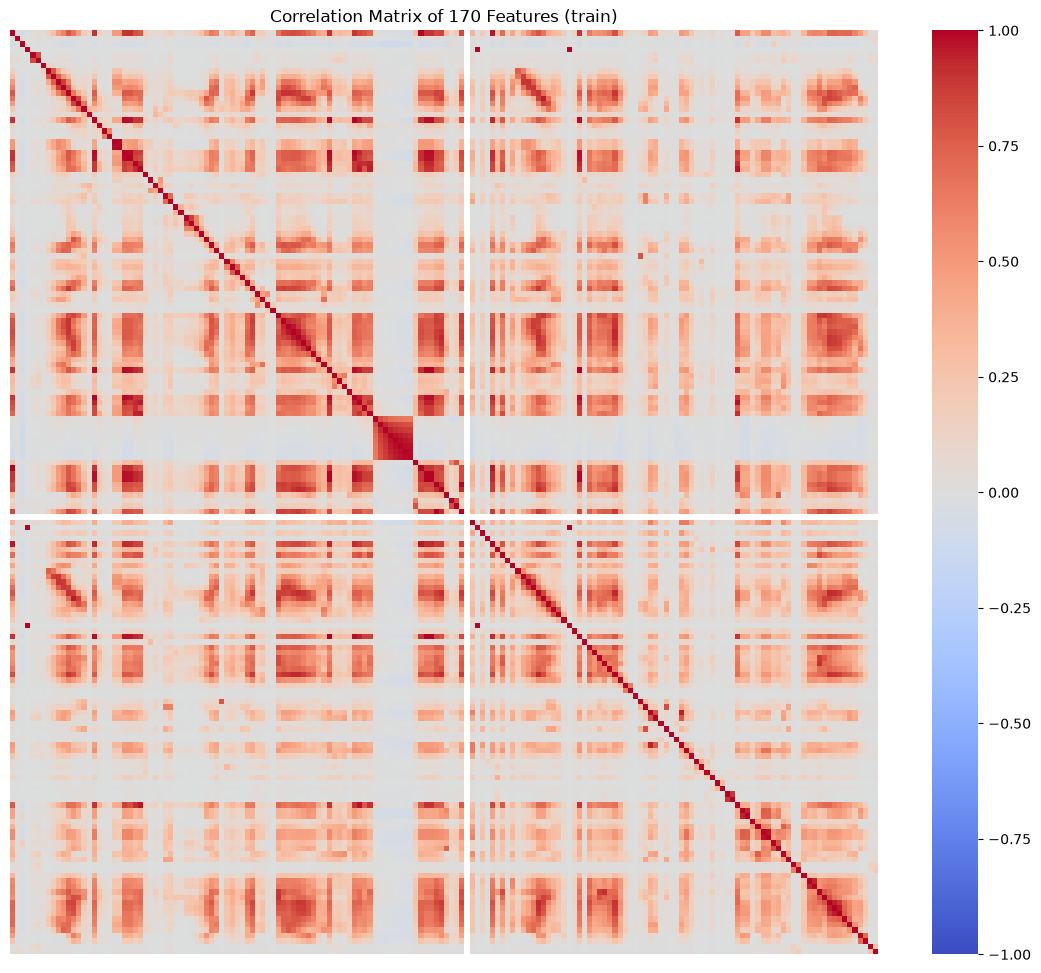

In [10]:
import seaborn as sns

corr = X_train.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False)
plt.title('Correlation Matrix of 170 Features (train)')
plt.show()


Many cells are red and I could not find any blue cells.
This means there is no strong negative correlation, and many features are positively correlated with each other.
Some groups of features are very highly correlated, so they carry similar (redundant) information.

#### (iv) Make scatter plots and box plots

In [11]:
top = cv.index[:13]   # floor(sqrt(170)) = 13
print(13, list(top))

df_top = X_train[top].copy()
df_top['class'] = train['class']

13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


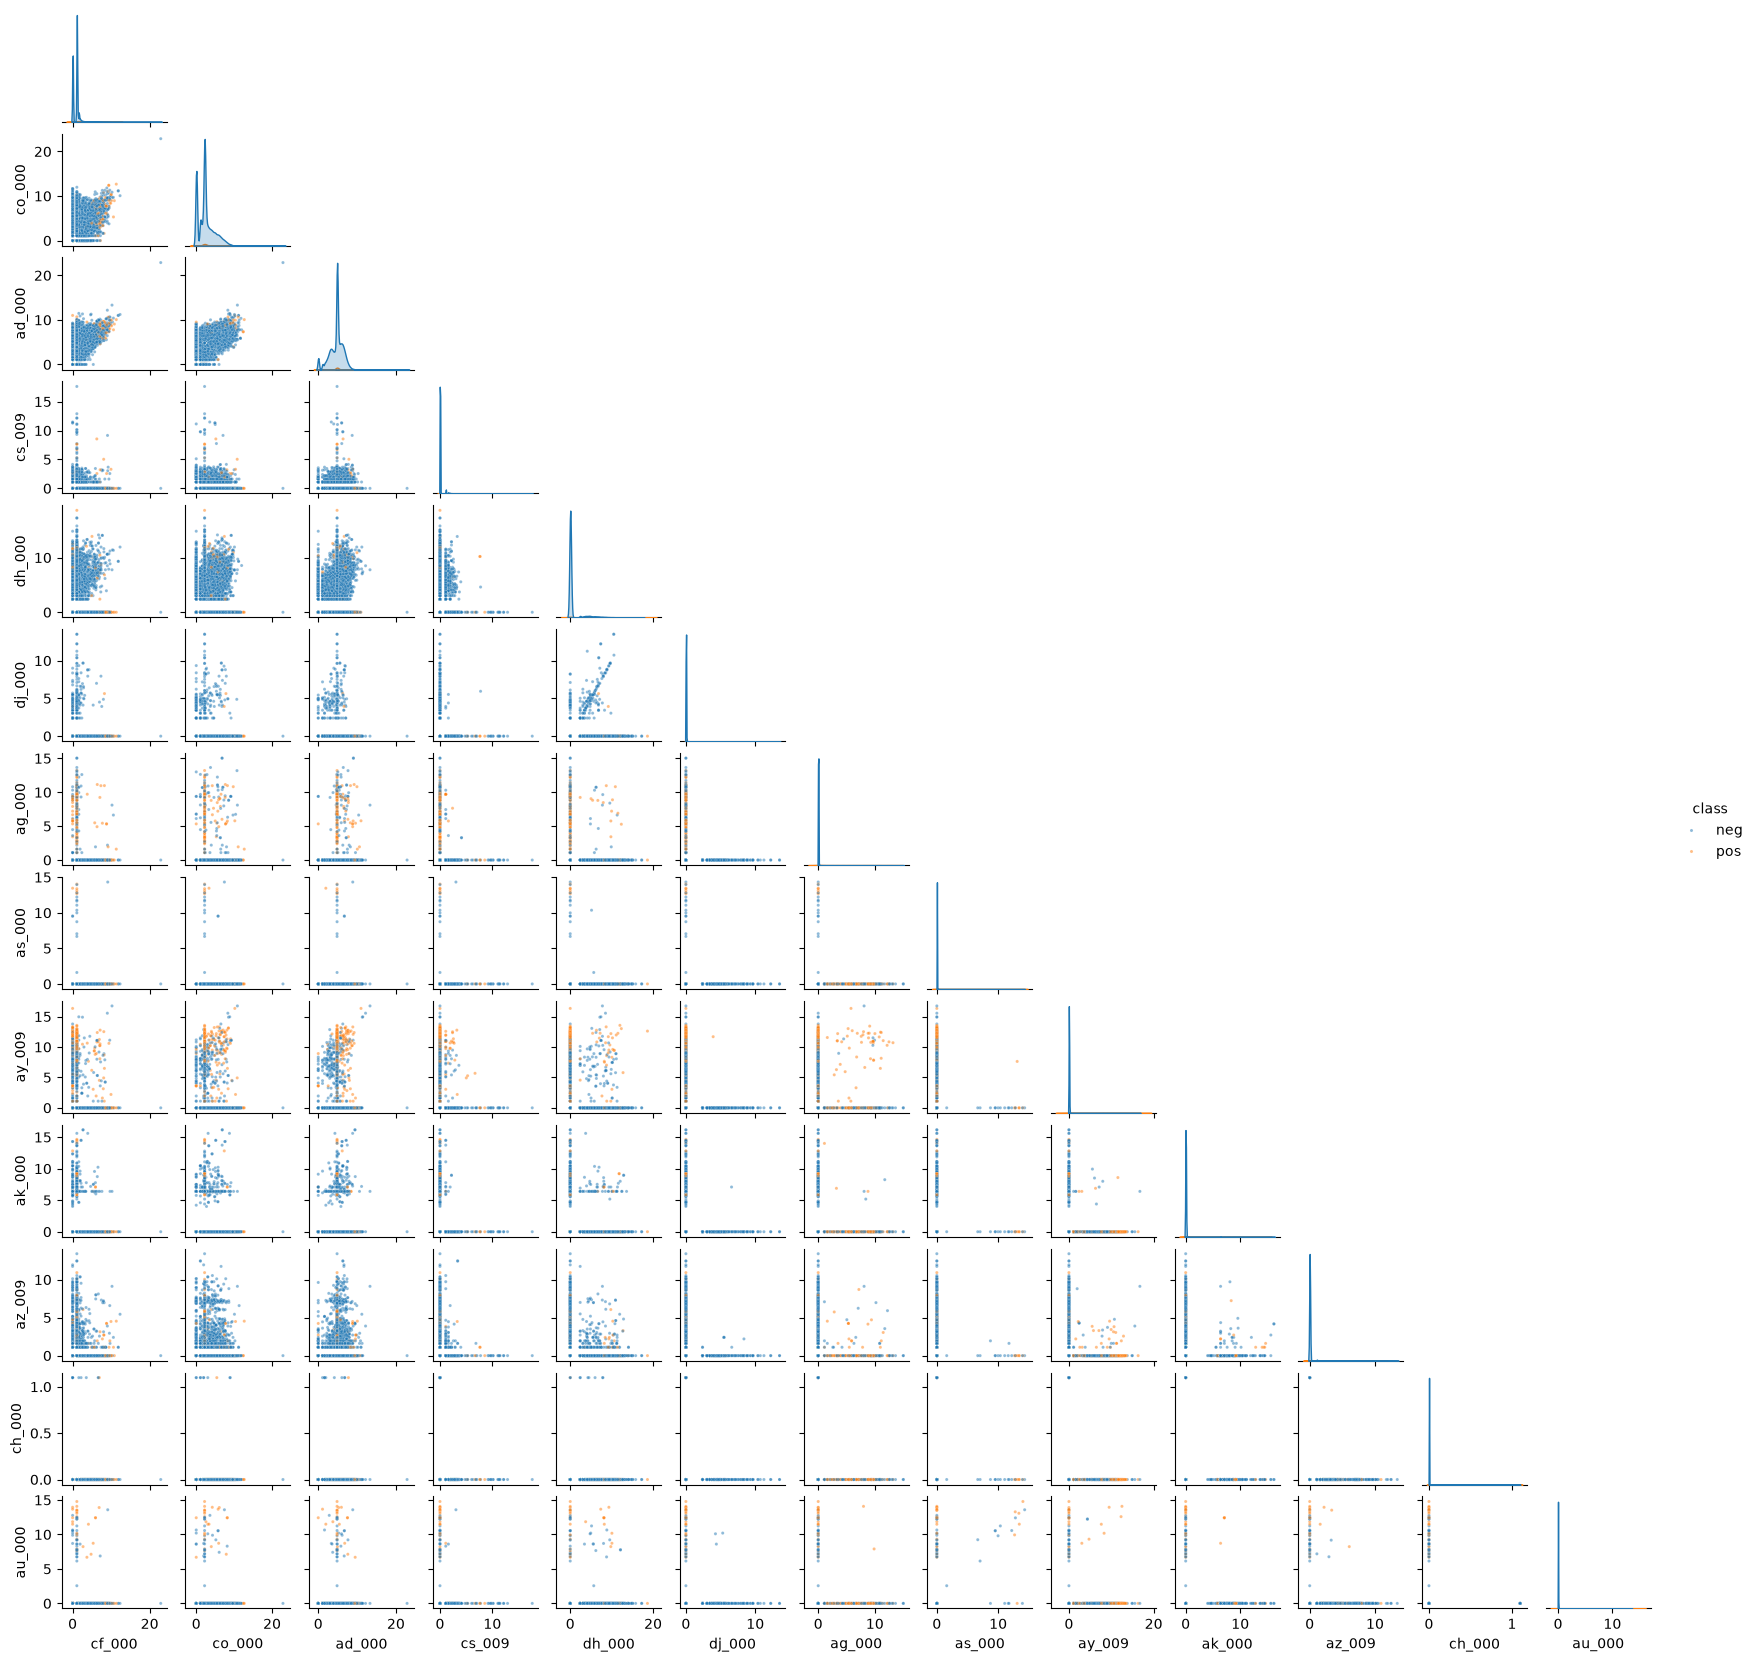

In [12]:
df_log = np.log1p(df_top[top])       
df_log['class'] = df_top['class']

sns.pairplot(df_log, hue='class', corner=True, height=1.3,
             plot_kws={'s': 5, 'alpha': 0.5})
plt.show()

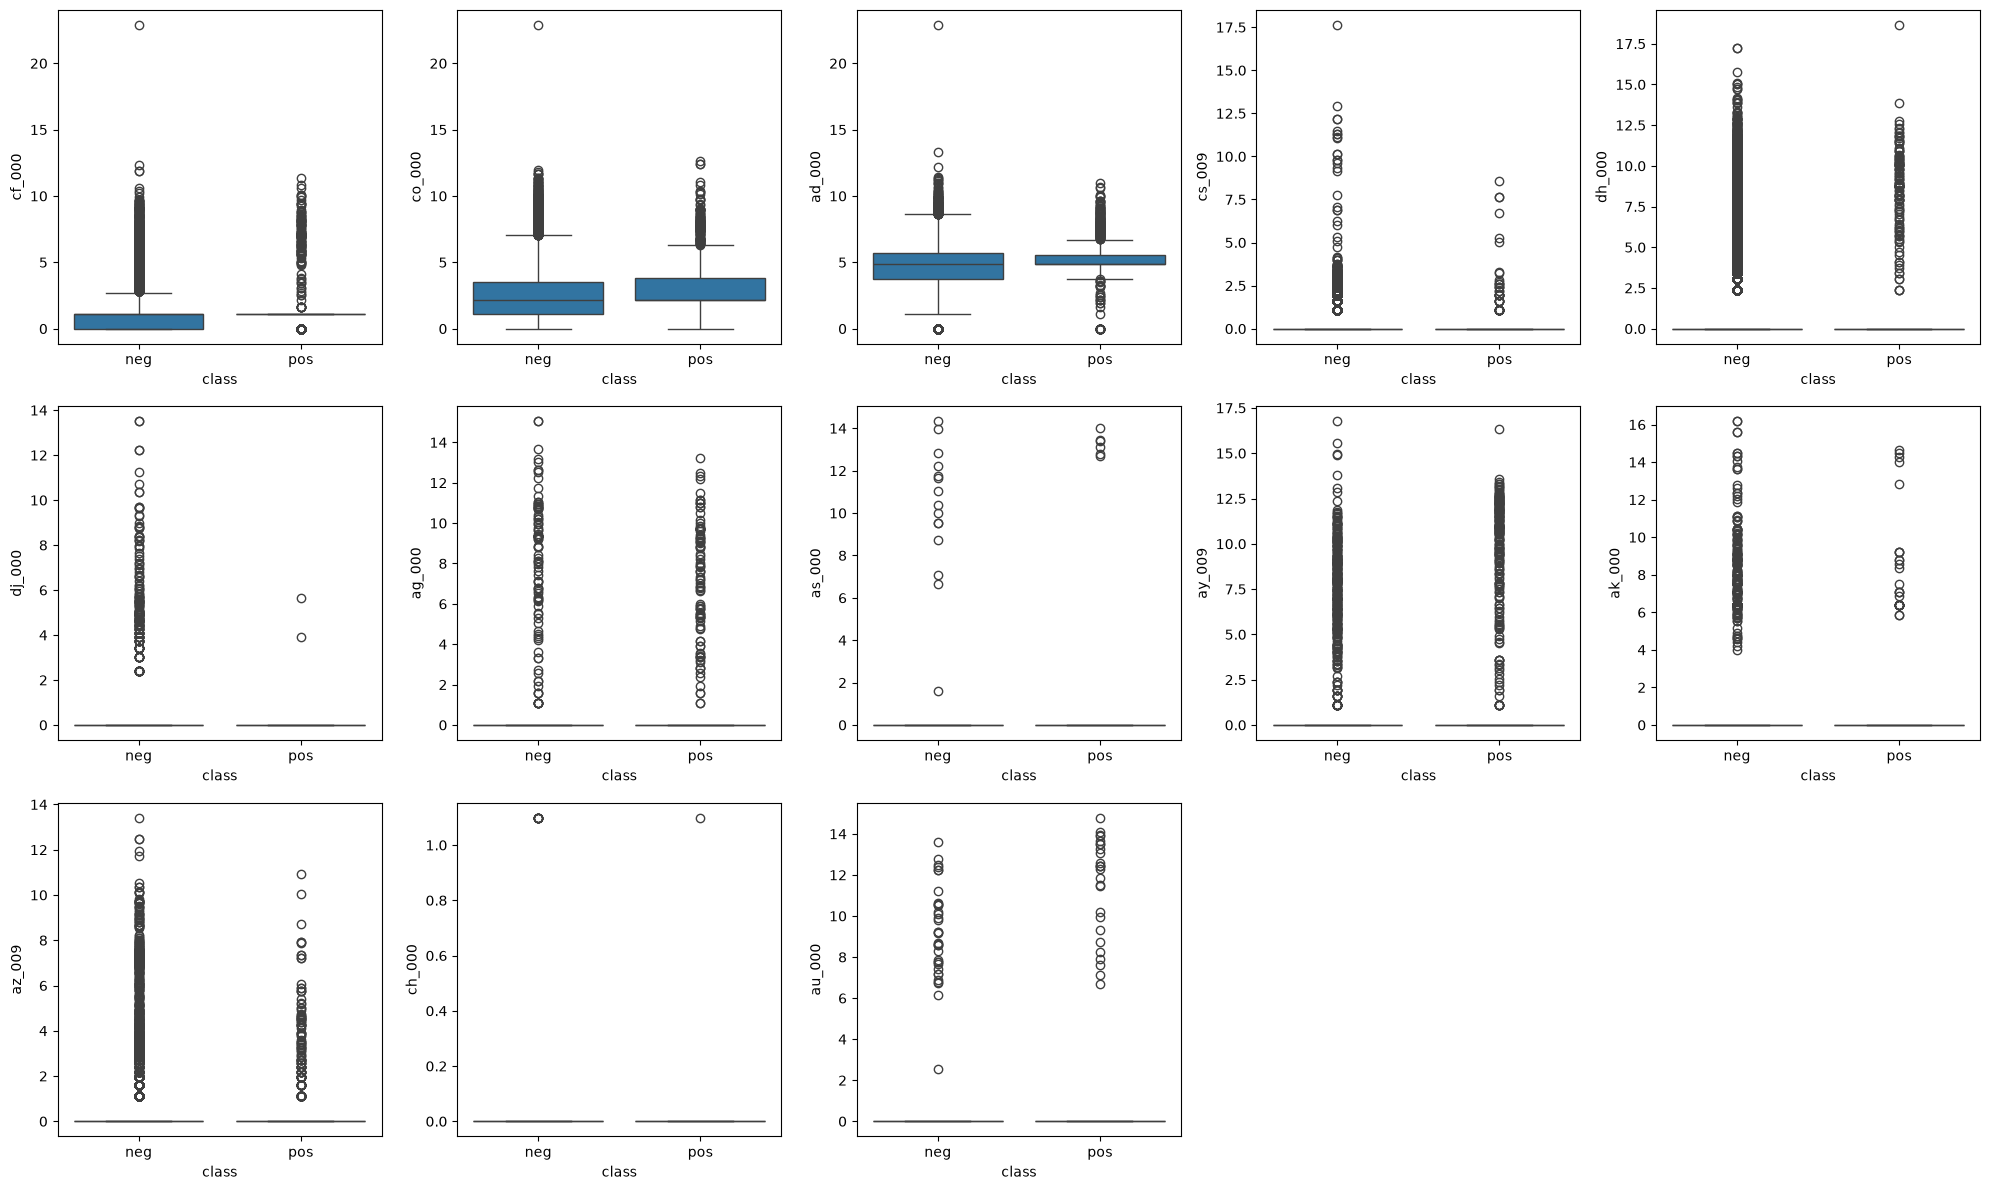

In [13]:
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(top):
    sns.boxplot(data=df_log, x='class', y=col, ax=axes[i])

for ax in axes[13:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [14]:
nonzero = (df_top[top] != 0).groupby(df_top['class']).mean().T
nonzero.round(3)

class,neg,pos
cf_000,0.640,0.796
co_000,0.784,0.964
ad_000,0.966,0.973
cs_009,0.048,0.052
dh_000,0.116,0.119
dj_000,0.003,0.002
ag_000,0.002,0.097
as_000,0.000,0.006
ay_009,0.006,0.207
ak_000,0.006,0.031


- I used log(1+x) for visualization because the raw values were too skewed to see any pattern.
- In the plots, most features are concentrated near 0, so the two classes almost completely overlap.
- Only a few features (cf_000, co_000, ad_000) show slight differences between the classes. 
- Therefore, I cannot draw conclusions about the significance of these features just by looking at the scatter plots.
- These features were selected by CV, which does not use the class labels, so a high CV does not mean the feature is important.


In [15]:
missing = train[top].isna().groupby(train['class']).mean().T
missing.round(3)

class,neg,pos
cf_000,0.241,0.645
co_000,0.241,0.645
ad_000,0.241,0.645
cs_009,0.011,0.004
dh_000,0.059,0.524
dj_000,0.059,0.524
ag_000,0.011,0.004
as_000,0.010,0.042
ay_009,0.011,0.005
ak_000,0.066,0.532


- Some features (e.g. ay_009, ag_000, az_009) have a much higher non-zero proportion in pos than in neg, which did not appear in the box plots.
- In pos, there are many more missing values than in neg, so filling them with the median may have affected the plots.

#### (v) Is this data set imbalanced?

In [16]:
train['class'].value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

There are 1,000 positive and 59,000 negative samples, so positives are only about 1.7% of the data.
**This is a highly imbalanced data set.**

A model that predicts every sample as negative would still get about 98.3% accuracy, so accuracy alone can be misleading.

### (c) Train a random forest

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay

def evaluate(model, name):
    # confusion matrix, misclassification rate and AUC for train and test; both ROC curves in one plot
    fig, ax = plt.subplots(figsize=(5, 4))
    for split, X, y in [('train', X_train, y_train), ('test', X_test, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        print(f'--- {name} {split} ---')
        display(pd.DataFrame(confusion_matrix(y, pred),
                             index=['actual neg', 'actual pos'],
                             columns=['pred neg', 'pred pos']))
        print('Misclassification:', round((pred != y).mean(), 4),
              '| AUC:', round(roc_auc_score(y, prob), 4))
        RocCurveDisplay.from_predictions(y, prob, name=f'{name} {split}', ax=ax)
    ax.set_title(f'ROC: {name}')
    plt.show()

--- RF train ---


,pred neg,pred pos
actual neg,59000,0
actual pos,1,999


Misclassification: 0.0 | AUC: 1.0
--- RF test ---


,pred neg,pred pos
actual neg,15610,15
actual pos,106,269


Misclassification: 0.0076 | AUC: 0.9928


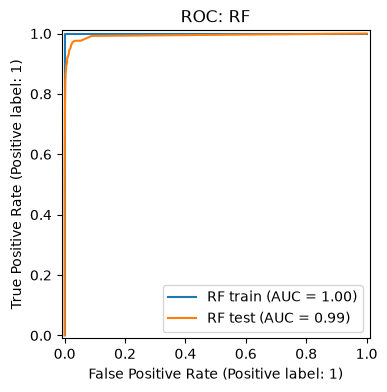

OOB error: 0.0061


In [18]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

evaluate(rf, 'RF')

print('OOB error:', round(1 - rf.oob_score_, 4))

**(c) Interpretation**
- Training set: 0 misclassifications and AUC = 1.0. The trees are grown to full depth, so the forest memorizes the training data (overfitting). The training performance does not tell us how well the model generalizes.
- OOB error (0.0061) is close to the test error (0.0076), so the OOB error is a reasonable estimate of the test error.
- Test confusion matrix: the model misses 106 of the 375 failed trucks (28%). Because the data is about 59:1 imbalanced, the model leans toward predicting the negative class.

### (d) Research class imbalance in random forest

**(d) Research: handling class imbalance in random forests**
- Class weights: give a larger penalty for misclassifying the minority class (sklearn `class_weight='balanced'`, weights inversely proportional to class frequencies).
- Balanced random forest: when bootstrapping for each tree, undersample the majority class so each tree sees a balanced sample.
- Resampling: oversample the minority class (e.g., SMOTE) or undersample the majority class.
- Threshold adjustment: classify as positive at a probability lower than 0.5.
- Here I used `class_weight='balanced'`.

/Users/sunminkim/Projects/Kim_Seonmin_HW6/.venv/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Balanced RF train ---


,pred neg,pred pos
actual neg,58986,14
actual pos,0,1000


Misclassification: 0.0002 | AUC: 1.0
--- Balanced RF test ---


,pred neg,pred pos
actual neg,15568,57
actual pos,99,276


Misclassification: 0.0098 | AUC: 0.9944


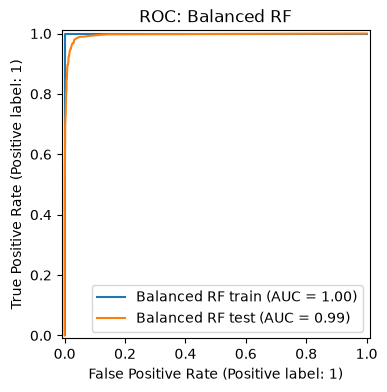

OOB error (sklearn): 0.0202
rows without OOB prediction: 1000 | all pos? True
OOB error (rows with OOB only): 0.0036


In [19]:
rf_bal = RandomForestClassifier(n_estimators=100, oob_score=True,
                                class_weight='balanced',
                                random_state=42, n_jobs=-1)
rf_bal.fit(X_train, y_train)

evaluate(rf_bal, 'Balanced RF')

print('OOB error (sklearn):', round(1 - rf_bal.oob_score_, 4))

# all 1000 positives were used by every tree, so they have no OOB prediction; recompute using rows with OOB only
oob = rf_bal.oob_decision_function_
has_oob = oob.sum(axis=1) > 0
print('rows without OOB prediction:', (~has_oob).sum(), '| all pos?', y_train[~has_oob].eq(1).all())
print('OOB error (rows with OOB only):', round((oob[has_oob].argmax(axis=1) != y_train[has_oob]).mean(), 4))

**(d) Comparison with (c) (test set)**
- Test error 0.0076 → 0.0098 (slightly worse), AUC 0.9928 → 0.9944 (slightly better).
- Missed failures 106 → 99 (slightly fewer), false alarms 15 → 57 (more). The model shifts toward catching more positives, but the effect is small.
- A likely reason: fully grown trees have pure leaves, so class weights have little effect on the final votes.
- OOB: sklearn reports 0.0202, but this is inflated. With balanced class weights, all 1,000 positive samples were used to train every tree, so they have no OOB prediction and are all counted as errors (1000/60000 ≈ 1.7%). Using only rows that have an OOB prediction gives 0.0036, but this is computed on negative samples only, so it is not directly comparable with the test error (0.0098).

### (e) XGBoost and Model Trees

**(e) Notes**
- In XGBoost (`binary:logistic`), `reg_alpha` is the L1 regularization term α. I chose α with 5-fold stratified cross-validation.
- Because the data is highly imbalanced, accuracy is not a good criterion for choosing α (Lesson 4, slide 34), so α is selected by F1 score. The CV misclassification error of the selected model is also reported to compare with the test error.
- Note: XGBoost does not fit an actual logistic regression at each node. It uses the logistic loss with L1 regularization to compute the leaf values.

In [20]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
alphas = [0, 0.01, 0.1, 1, 10, 100]

xgb = XGBClassifier(objective='binary:logistic', n_estimators=200,
                    tree_method='hist', random_state=42, n_jobs=-1)
grid = GridSearchCV(xgb, {'reg_alpha': alphas}, cv=cv5, 
                    scoring={'f1': 'f1', 'acc': 'accuracy'}, refit='f1')  # pick alpha by F1 (imbalanced data, Lesson 4 slide 34)
grid.fit(X_train, y_train)

print('best alpha:', grid.best_params_['reg_alpha'])
print('5-fold CV F1:', round(grid.best_score_, 4))
print('5-fold CV error:', round(1 - grid.cv_results_['mean_test_acc'][grid.best_index_], 4))
pd.DataFrame(grid.cv_results_)[['param_reg_alpha', 'mean_test_f1', 'mean_test_acc']]

best alpha: 0.01
5-fold CV F1: 0.8022
5-fold CV error: 0.0062


,param_reg_alpha,mean_test_f1,mean_test_acc
0,0.00,0.796576,0.993733
1,0.01,0.802222,0.993800
2,0.10,0.799332,0.993733
3,1.00,0.795424,0.993617
4,10.00,0.710831,0.991067
5,100.00,0.621061,0.988433


--- XGB train ---


,pred neg,pred pos
actual neg,59000,0
actual pos,0,1000


Misclassification: 0.0 | AUC: 1.0


--- XGB test ---


,pred neg,pred pos
actual neg,15612,13
actual pos,82,293


Misclassification: 0.0059 | AUC: 0.9939


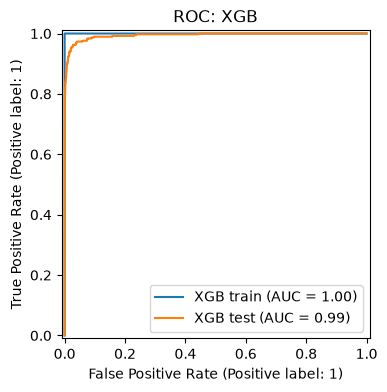

In [21]:
xgb_best = grid.best_estimator_
evaluate(xgb_best, 'XGB')

**(e) Results**
- Selected α = 0.01 (CV F1 = 0.80).
- 5-fold CV error 0.0062 vs. test error 0.0059: the CV estimate is very close to the test error.
- Training error is 0 and training AUC is 1.0, so the model fits the training data perfectly, but it still generalizes well (test AUC 0.9939). On the test set it misses 82 of 375 failed trucks.

### (f) Use SMOTE to pre-process your data

**(f) Right vs. wrong way of cross-validation with SMOTE**
- Wrong: apply SMOTE to the whole training set first and then run CV. The validation folds then contain synthetic positives created from real positives in the training folds, so information leaks and the CV error is too optimistic.
- Right: in each CV fold, apply SMOTE **only to the training part** and keep the validation part as original data. This is implemented with an imblearn `Pipeline`.

In [22]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(objective='binary:logistic', n_estimators=200,
                          tree_method='hist', random_state=42, n_jobs=-1)),
])
grid_s = GridSearchCV(pipe, {'xgb__reg_alpha': alphas}, cv=cv5, 
                    scoring={'f1': 'f1', 'acc': 'accuracy'}, refit='f1')  # pick alpha by F1 (imbalanced data, Lesson 4 slide 34)
grid_s.fit(X_train, y_train)

print('best alpha:', grid_s.best_params_['xgb__reg_alpha'])
print('5-fold CV F1:', round(grid_s.best_score_, 4))
print('5-fold CV error:', round(1 - grid_s.cv_results_['mean_test_acc'][grid_s.best_index_], 4))
pd.DataFrame(grid_s.cv_results_)[['param_xgb__reg_alpha', 'mean_test_f1', 'mean_test_acc']]

best alpha: 0
5-fold CV F1: 0.8189
5-fold CV error: 0.006


,param_xgb__reg_alpha,mean_test_f1,mean_test_acc
0,0.00,0.818865,0.994000
1,0.01,0.817425,0.993933
2,0.10,0.810323,0.993750
3,1.00,0.818627,0.993917
4,10.00,0.778255,0.992167
5,100.00,0.625974,0.982417


--- XGB+SMOTE train ---


,pred neg,pred pos
actual neg,59000,0
actual pos,0,1000


Misclassification: 0.0 | AUC: 1.0


--- XGB+SMOTE test ---


,pred neg,pred pos
actual neg,15564,61
actual pos,56,319


Misclassification: 0.0073 | AUC: 0.9895


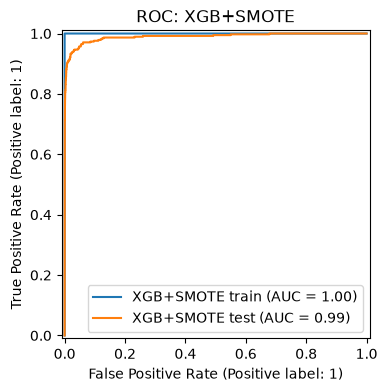

In [23]:
xgb_smote = grid_s.best_estimator_
evaluate(xgb_smote, 'XGB+SMOTE')

In [24]:
# compare test performance of the 4 models
models = {'RF': rf, 'Balanced RF': rf_bal, 'XGB': xgb_best, 'XGB+SMOTE': xgb_smote}
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    rows.append({'model': name,
                 'test error': round((pred != y_test).mean(), 4),
                 'test AUC': round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 4),
                 'missed pos (FN)': cm[1, 0],
                 'false alarm (FP)': cm[0, 1]})
pd.DataFrame(rows)

,model,test error,test AUC,missed pos (FN),false alarm (FP)
0,RF,0.0076,0.9928,106,15
1,Balanced RF,0.0098,0.9944,99,57
2,XGB,0.0059,0.9939,82,13
3,XGB+SMOTE,0.0073,0.9895,56,61


**(f) Comparison: (e) no SMOTE vs. (f) SMOTE**
- 5-fold CV error: 0.0062 (α = 0.01) vs. 0.0060 (α = 0); test error: 0.0059 vs. 0.0073. In both cases the CV error is close to the test error.
- Test AUC: 0.9939 vs. 0.9895.
- Missed failures 82 → 56 (much fewer), false alarms 13 → 61 (more).
- Conclusion: the model without SMOTE has slightly lower overall error and AUC, but SMOTE detects more failed trucks (recall 78% → 85%). If missing a failure is more costly than a false alarm, the SMOTE model is more useful in practice.
- Cross-validation was done the right way: SMOTE is applied only to the training folds through the Pipeline.

## 2. ISLR 6.6.3

As s increases from 0, the constraint on the coefficients becomes weaker, so the model becomes more flexible (s = 0 gives the null model, and a large s gives least squares).

(a) iv. Steadily decrease. A larger s allows more possible coefficient choices, so the model can fit the training data better and training RSS keeps going down.

(b) ii. Decrease initially, then eventually increase in a U shape. At first, the extra flexibility reduces bias and test RSS goes down, but when s becomes too large the model overfits and test RSS goes up again.

(c) iii. Steadily increase. When s = 0 all coefficients are 0, so the variance is 0. As s grows, the coefficients depend more on the training data, so the variance keeps increasing.

(d) iv. Steadily decrease. A more flexible model can capture the true relationship better, so the squared bias keeps going down.

(e) v. Remain constant. Irreducible error comes from the noise in the data itself, not from the model, so changing s does not affect it.

## 3. ISLR 6.6.5

Since x11 = x12 and x21 = x22, write x1 = x11 = x12 and x2 = x21 = x22. Then the prediction for observation i is (β1 + β2)·xi, so the RSS depends only on the sum β1 + β2.

(a) Ridge: minimize (y1 − β1·x11 − β2·x12)² + (y2 − β1·x21 − β2·x22)² + λ(β1² + β2²)

(b) The RSS only depends on β1 + β2. For a fixed sum β1 + β2 = c, the penalty β1² + β2² is smallest when the sum is split equally (for example, c = 4: (4,0) → 16, (3,1) → 10, (2,2) → 8). So the ridge solution satisfies β1 = β2.

(c) Lasso: minimize (y1 − β1·x11 − β2·x12)² + (y2 − β1·x21 − β2·x22)² + λ(|β1| + |β2|)

(d) Again the RSS only depends on β1 + β2 = c. If β1 and β2 have the same sign, the penalty |β1| + |β2| = |c| is the same for every split (for example, c = 4: (4,0), (3,1), (2,2) all give 4). If they have different signs, the penalty is larger (for example, (5,−1) gives 6), so those are not optimal. Therefore the lasso solution is not unique: every point on the line segment β1 + β2 = c with β1, β2 having the same sign as c is a solution (for c > 0, from (c, 0) to (0, c)).

## 4. ISLR 8.4.5

The ten estimates of P(Class is Red | X) are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

Majority vote: 6 of the 10 estimates are greater than 0.5, so 6 trees vote Red and 4 trees vote Green. The final classification is Red.

Average probability: the sum is 4.5, so the average is 4.5 / 10 = 0.45. Since 0.45 < 0.5, the final classification is Green.

The two approaches give different answers because majority vote only counts the votes, while averaging also uses how confident each tree is. The 4 Green trees are very confident (0.1 to 0.2), while the 6 Red trees are only slightly above 0.5.


## 5. ISLR 9.7.3

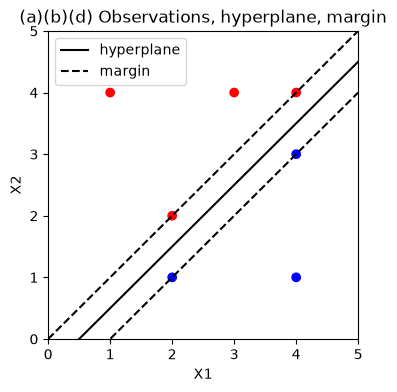

In [25]:
X1 = [3, 2, 4, 1, 2, 4, 4]
X2 = [4, 2, 4, 4, 1, 3, 1]
color = ['red'] * 4 + ['blue'] * 3

plt.figure(figsize=(4, 4))
plt.scatter(X1, X2, c=color)
plt.xlabel('X1'); plt.ylabel('X2')
plt.xlim(0, 5); plt.ylim(0, 5)
x = np.linspace(0, 5, 100)
plt.plot(x, x - 0.5, 'k-', label='hyperplane')
plt.plot(x, x, 'k--'); plt.plot(x, x - 1, 'k--', label='margin')
plt.legend()
plt.title('(a)(b)(d) Observations, hyperplane, margin')
plt.show()

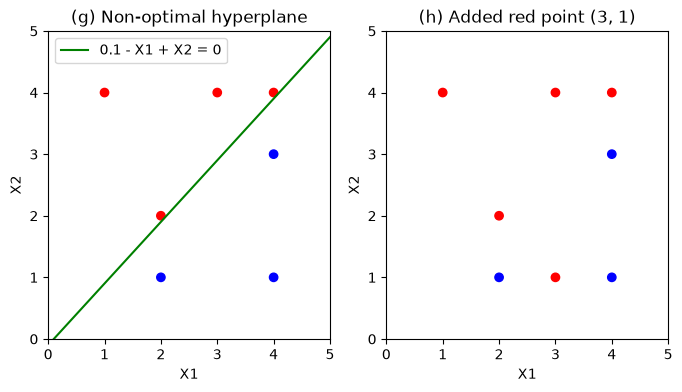

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
x = np.linspace(0, 5, 100)

axes[0].scatter(X1, X2, c=color)
axes[0].plot(x, x - 0.1, 'g-', label='0.1 - X1 + X2 = 0')
axes[0].set_title('(g) Non-optimal hyperplane')
axes[0].legend()

axes[1].scatter(X1 + [3], X2 + [1], c=color + ['red'])
axes[1].set_title('(h) Added red point (3, 1)')

for ax in axes:
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_xlabel('X1'); ax.set_ylabel('X2')
plt.show()

(a) See the plot above.

(b) The closest pairs of opposite classes are Red (2,2) / Blue (2,1) and Red (4,4) / Blue (4,3). The optimal separating hyperplane passes through their midpoints (2, 1.5) and (4, 3.5), so it is X2 = X1 − 0.5, i.e. 0.5 − X1 + X2 = 0.

(c) Classify to Red if 0.5 − X1 + X2 > 0, and classify to Blue otherwise. (β0 = 0.5, β1 = −1, β2 = 1)

(d) The margin boundaries are X2 = X1 (Red side) and X2 = X1 − 1 (Blue side), shown as dashed lines. The margin is 0.5 / √2 ≈ 0.354.

(e) The support vectors are Red (2,2), (4,4) and Blue (2,1), (4,3).

(f) The 7th observation (4,1) is not a support vector and is far from the margin, so a slight movement would not change the maximal margin hyperplane.

(g) 0.1 − X1 + X2 = 0 separates the two classes but is not optimal, because it is much closer to the Red points and the margin is smaller.

(h) Adding a Red observation at (3,1), between the Blue points (2,1) and (4,1), makes the two classes no longer separable by a hyperplane.

## AI Usage Disclosure
- Tool: Claude (Claude Code)
- Used for:
  - Explanations of concepts (missing value imputation, CV, correlation heatmap, confusion matrix, OOB, class imbalance, SMOTE, lasso/ridge, SVM margin) and debugging (read_csv errors, heatmap vmin typo).
  - Generating the code for parts 1(c)–(f) and drafting the interpretation notes for 1(c)–(f), which I reviewed.
  - ISLR 6.6.3, 6.6.5, 8.4.5, 9.7.3: Claude guided me step by step with questions and I worked out the answers; Claude helped write the final English sentences.
- Parts 1(a)–(b) code and the interpretations in 1(b) were written by me.